# Project 11: Handwritten Digit Classification Using CNN

## Introduction

- A **CNN (Convolutional Neural Network)** is a type of deep learning model designed mainly for image data
- It uses **convolutional layers** to automatically learn features like edges, curves, and patterns from images
- **Pooling layers** reduce the size of the feature maps while keeping important information
- In this project, a CNN is built to classify handwritten digits (0–9) from the **MNIST dataset**
- MNIST contains 70,000 grayscale images of handwritten digits, each of size 28×28 pixels

## Task 1: Load and Preprocess the MNIST Dataset

Steps:
- Load the MNIST dataset directly from Keras
- Normalize pixel values from 0–255 to 0–1
- Reshape images to include a channel dimension (required by CNN)
- One-hot encode the labels

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

In [2]:
# Load dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Original shape - Train:", X_train.shape, "| Test:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original shape - Train: (60000, 28, 28) | Test: (10000, 28, 28)


In [3]:
# Normalize pixel values to 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

In [4]:
# Reshape to (samples, height, width, channels)
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

In [5]:
# One-hot encode labels
y_train_enc = to_categorical(y_train, 10)
y_test_enc = to_categorical(y_test, 10)

In [6]:
print("After reshape - Train:", X_train.shape, "| Test:", X_test.shape)
print("Label shape - Train:", y_train_enc.shape)
print("Sample labels (first 5):", y_train[:5])

After reshape - Train: (60000, 28, 28, 1) | Test: (10000, 28, 28, 1)
Label shape - Train: (60000, 10)
Sample labels (first 5): [5 0 4 1 9]


## Task 2: Build and Train a Basic CNN Model

Architecture:
- **Conv2D (32 filters, 3×3)** — learns basic features like edges
- **MaxPooling2D (2×2)** — reduces size, keeps important features
- **Conv2D (64 filters, 3×3)** — learns more complex patterns
- **MaxPooling2D (2×2)** — reduces size again
- **Flatten** — converts 2D feature maps to 1D
- **Dense (128)** — fully connected layer
- **Dense (10, Softmax)** — output layer for 10 digit classes

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

# Build the CNN
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# Train the model
history = model.fit(X_train, y_train_enc,
                    epochs=5,
                    batch_size=64,
                    validation_split=0.1,
                    verbose=1)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 49s 56ms/step - accuracy: 0.9472 - loss: 0.1778 - val_accuracy: 0.9823 - val_loss: 0.0623
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 55ms/step - accuracy: 0.9839 - loss: 0.0529 - val_accuracy: 0.9858 - val_loss: 0.0474
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 44s 53ms/step - accuracy: 0.9886 - loss: 0.0365 - val_accuracy: 0.9890 - val_loss: 0.0389
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 46s 54ms/step - accuracy: 0.9913 - loss: 0.0274 - val_accuracy: 0.9920 - val_loss: 0.0291
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 81s 53ms/step - accuracy: 0.9939 - loss: 0.0193 - val_accuracy: 0.9908 - val_loss: 0.0326


## Task 3: Evaluate the Model

Evaluation includes:
- Overall test accuracy
- Confusion matrix — shows which digits get misclassified
- Classification report — precision, recall, and F1-score for each digit
- Sample predictions — visual check on a few test images

In [9]:
# Test accuracy
test_loss, test_acc = model.evaluate(X_test, y_test_enc, verbose=0)
print(f"Test Accuracy: {round(test_acc * 100, 2)}%")
print(f"Test Loss: {round(test_loss, 4)}")

Test Accuracy: 99.04%
Test Loss: 0.0283


In [10]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
# Predictions
y_pred_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

In [12]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

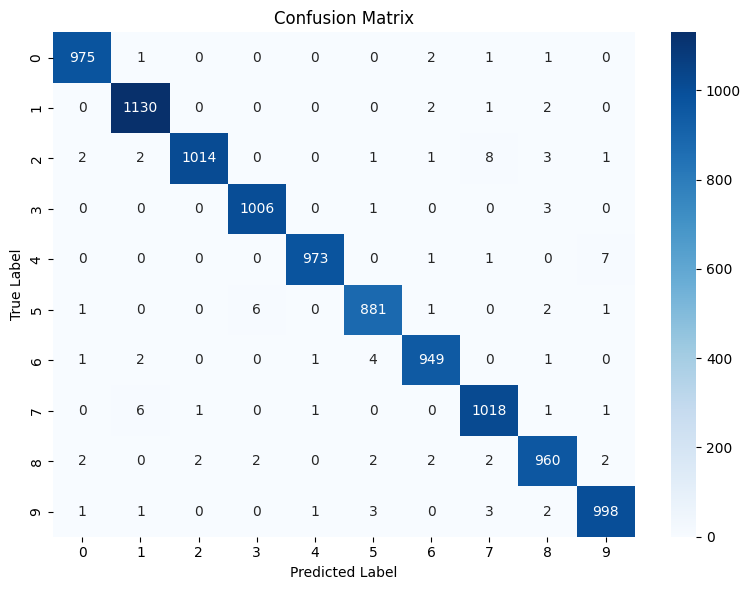

In [13]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.show()

In [14]:
# Classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=[str(i) for i in range(10)]))

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       1.00      0.98      0.99      1032
           3       0.99      1.00      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      0.99      0.99      1028
           8       0.98      0.99      0.99       974
           9       0.99      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



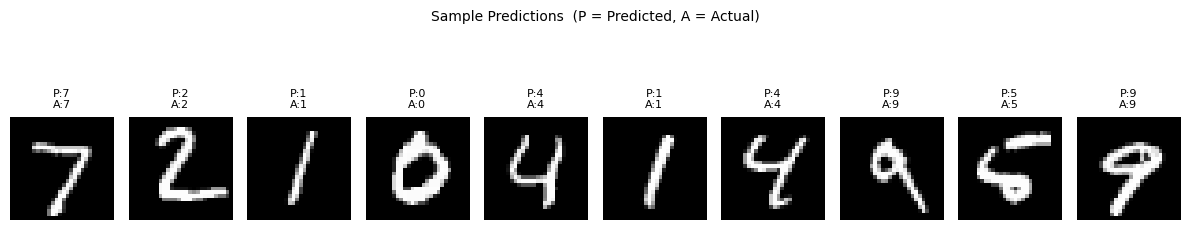

In [15]:
# Sample predictions (first 10 test images)
plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
    plt.title(f"P:{y_pred[i]}\nA:{y_test[i]}", fontsize=8)
    plt.axis('off')
plt.suptitle('Sample Predictions  (P = Predicted, A = Actual)', fontsize=10)
plt.tight_layout()
plt.show()

## Conclusion

- The MNIST dataset was loaded, normalised, and reshaped to fit the CNN input format
- A basic CNN with two convolutional layers, two pooling layers, and two dense layers was built and trained for 5 epochs
- The model achieved high accuracy on the test set, showing that CNNs are well suited for image classification tasks
- The confusion matrix showed that most digits are classified correctly; digits like 4 and 9 or 3 and 5 may occasionally be confused due to their visual similarity
- The classification report confirmed consistent precision, recall, and F1-score across all 10 digit classes
- Overall, CNNs outperform regular feedforward networks on image data because they can automatically learn spatial features through convolutional filters